In [51]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [52]:
DATASET_PATH = "../data/boats/input"

image_files = sorted([
    f for f in os.listdir(DATASET_PATH)
    if f.endswith(".jpg")
])

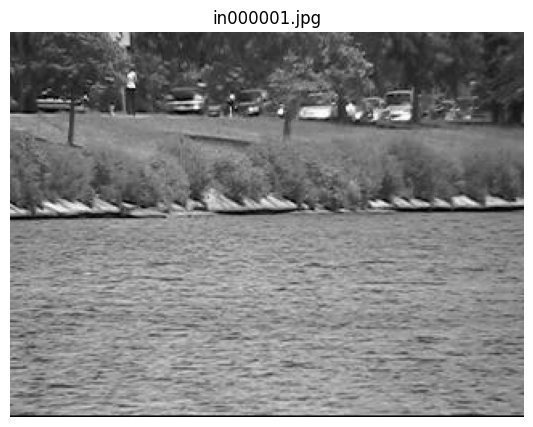

In [53]:
img_path = os.path.join(DATASET_PATH, image_files[0])

img = cv2.imread(img_path)

img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(15,5))
plt.imshow(img, cmap='gray')
plt.title(image_files[0])
plt.axis('off')
plt.show()


In [54]:
frames = []

for file in image_files[1900:2100]:

    img_path = os.path.join(DATASET_PATH, file)

    frame = cv2.imread(img_path,
                       cv2.IMREAD_GRAYSCALE)

    gray = cv2.resize(frame, (160,120))

    gray = gray.astype(np.float64) /255

    x = gray.reshape(-1)

    frames.append(x)

# Build matrix properly
D = np.stack(frames, axis=1)

print(D.shape)

(19200, 200)


In [55]:
def soft_threshold(X, tau):

    return np.sign(X) * np.maximum(np.abs(X) - tau, 0)

In [56]:
def svd_threshold(X, tau):

    U, S, VT = np.linalg.svd(X, full_matrices=False)

    S_threshold = np.maximum(S - tau, 0)

    return np.dot(U * S_threshold, VT)

In [57]:
def rpca(D, lamb=None, mu=None,
         max_iter=150, tol=1e-7):

    m, n = D.shape

    if lamb is None:
        lamb = 1 / np.sqrt(max(m, n))

    if mu is None:
        mu = 10 / np.linalg.norm(D, 2)

    # Initialize
    L = np.zeros_like(D)
    S = np.zeros_like(D)
    Y = np.zeros_like(D)

    norm_D = np.linalg.norm(D, ord='fro')

    for itr in range(max_iter):

        # Update Low Rank
        L = svd_threshold(D - S + (1/mu)*Y,
                          1/mu)

        # Update Sparse
        S = soft_threshold(D - L + (1/mu)*Y,
                           lamb/mu)

        # Residual
        Z = D - L - S

        # Update multiplier
        Y = Y + mu * Z

        error = np.linalg.norm(Z, ord='fro') / norm_D

    print(f"Iteration {itr+1}: error = {error:.8f}")

    return L, S

In [58]:
L, S = rpca(D)

Iteration 150: error = 0.00272731


In [59]:
background = L.T.reshape(-1, 120, 160)

foreground = S.T.reshape(-1, 120, 160)

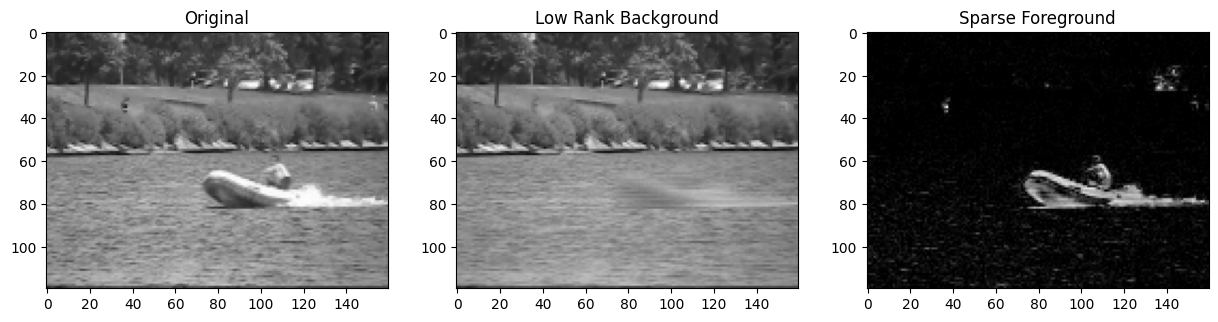

In [10]:
idx = 80

original = D[:, idx].reshape(120,160)

bg = background[idx]

fg = np.abs(foreground[idx])

plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.imshow(original, cmap='gray')
plt.title("Original")

plt.subplot(1,3,2)
plt.imshow(bg, cmap='gray')
plt.title("Low Rank Background")

plt.subplot(1,3,3)
plt.imshow(fg, cmap='gray')
plt.title("Sparse Foreground")

plt.show()

In [60]:
print("Foreground min:", foreground.min())
print("Foreground max:", foreground.max())
print("Foreground mean:", foreground.mean())
print("Foreground std:", foreground.std())

Foreground min: -0.7356693875350421
Foreground max: 0.5750413366183637
Foreground mean: 0.0005342423048512322
Foreground std: 0.03706619877173943


In [61]:
thresholds = [0.01, 0.02, 0.03, 0.05, 0.07, 0.10, 0.15]

for t in thresholds:
    mask = np.abs(foreground) > t
    percentage = 100 * np.mean(mask)

    print(f"Threshold = {t:.2f} | Foreground pixels = {percentage:.2f}%")

Threshold = 0.01 | Foreground pixels = 32.20%
Threshold = 0.02 | Foreground pixels = 17.22%
Threshold = 0.03 | Foreground pixels = 10.53%
Threshold = 0.05 | Foreground pixels = 5.11%
Threshold = 0.07 | Foreground pixels = 3.22%
Threshold = 0.10 | Foreground pixels = 2.11%
Threshold = 0.15 | Foreground pixels = 1.34%


In [62]:
GT_PATH = "../data/boats/groundtruth"

gt_files = sorted([
    f for f in os.listdir(GT_PATH)
    if f.endswith(".png")
])

print("Number of GT files:", len(gt_files))
print(gt_files[:5])

Number of GT files: 7999
['gt000001.png', 'gt000002.png', 'gt000003.png', 'gt000004.png', 'gt000005.png']


In [64]:
selected_files = image_files[1900:2100]

selected_ids = [
    int(f[2:8])
    for f in selected_files
]

print(selected_ids[:10])
print(len(selected_ids))

[1901, 1902, 1903, 1904, 1905, 1906, 1907, 1908, 1909, 1910]
200


In [65]:
gt_masks = []
valid_masks = []

for frame_id in selected_ids:

    gt_path = os.path.join(
        GT_PATH,
        gt_dict[frame_id]
    )

    gt_frame = cv2.imread(
        gt_path,
        cv2.IMREAD_GRAYSCALE
    )

    gt_frame = cv2.resize(
        gt_frame,
        (160, 120),
        interpolation=cv2.INTER_NEAREST
    )

    # 255 = foreground
    gt_binary = (gt_frame == 255).astype(np.uint8)

    # Evaluate only:
    # 0   = background
    # 50  = shadow/background
    # 255 = foreground
    valid = (
        (gt_frame == 0) |
        (gt_frame == 50) |
        (gt_frame == 255)
    )

    gt_masks.append(gt_binary)
    valid_masks.append(valid)

gt_masks = np.stack(gt_masks)
valid_masks = np.stack(valid_masks)

print("GT shape:", gt_masks.shape)
print("GT unique:", np.unique(gt_masks))

print("Valid shape:", valid_masks.shape)
print("Valid pixels:", np.sum(valid_masks))
print("Ignored pixels:", np.sum(~valid_masks))

GT shape: (200, 120, 160)
GT unique: [0 1]
Valid shape: (200, 120, 160)
Valid pixels: 1988679
Ignored pixels: 1851321


In [66]:
results_rpca = []

thresholds = [0.01, 0.02, 0.03, 0.05, 0.07, 0.10, 0.15]

# Ground truth
y_true = np.concatenate([
    g.flatten() for g in gt_masks
])

for threshold in thresholds:

    # Generate foreground masks from RPCA sparse component
    pred_masks = []

    for i in range(200):

        foreground_frame = np.abs(
            foreground[i]
        )

        mask = (
            foreground_frame > threshold
        ).astype(np.uint8)

        pred_masks.append(mask)

    # Flatten predictions
    y_pred = np.concatenate([
        m.flatten() for m in pred_masks
    ])

    # Confusion matrix
    TP = np.sum((y_pred == 1) & (y_true == 1))
    TN = np.sum((y_pred == 0) & (y_true == 0))
    FP = np.sum((y_pred == 1) & (y_true == 0))
    FN = np.sum((y_pred == 0) & (y_true == 1))

    # Metrics
    precision = TP / (TP + FP + 1e-8)

    recall = TP / (TP + FN + 1e-8)

    f1 = (
        2 * precision * recall
        / (precision + recall + 1e-8)
    )

    accuracy = (
        (TP + TN)
        / (TP + TN + FP + FN + 1e-8)
    )

    iou = (
        TP
        / (TP + FP + FN + 1e-8)
    )

    # Store results
    results_rpca.append({
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "accuracy": accuracy,
        "iou": iou
    })

In [67]:
df = pd.DataFrame(results_rpca)
df.head()

,threshold,precision,recall,f1,accuracy,iou
0,0.01,0.034511,0.951220,0.066605,0.688585,0.034450
1,0.02,0.062706,0.924332,0.117445,0.837732,0.062386
2,0.03,0.099541,0.897334,0.179203,0.903984,0.098420
3,0.05,0.190822,0.835310,0.310673,0.956702,0.183903
4,0.07,0.278794,0.769653,0.409319,0.974053,0.257323


In [68]:
best = df.loc[df["f1"].idxmax()]

print(best)

threshold    0.150000
precision    0.461367
recall       0.530231
f1           0.493408
accuracy     0.987282
iou          0.327499
Name: 6, dtype: float64
